# 15 보호된 장비 그룹 검증과 최종 시간 Holdout

장비별 별도 모델이 아닌 여러 장비의 공통 모델입니다. 그룹 검증에서는 학습01–06/검증07–08 장비를 분리하고 최종 시간 Holdout을 제외했습니다. 사전 규칙으로 B 최대가용 기준 모델과 두 숫자 임계값을 동결한 뒤 기존20대의 마지막20% 시간 구간을 한 번 예측했습니다.

이 Notebook은 저장된 결과를 읽고 검증합니다. 모델 재학습·Holdout 재추론·임계값 탐색을 수행하지 않습니다. 두 운영점 모두 연구 결과이며 현장 운영 기준을 승인한 것은 아닙니다.

실행 환경: C:\Users\fl27\anaconda3\envs\phm2018\python.exe | 최종 모델: B | Holdout 전체 추론: 1 회


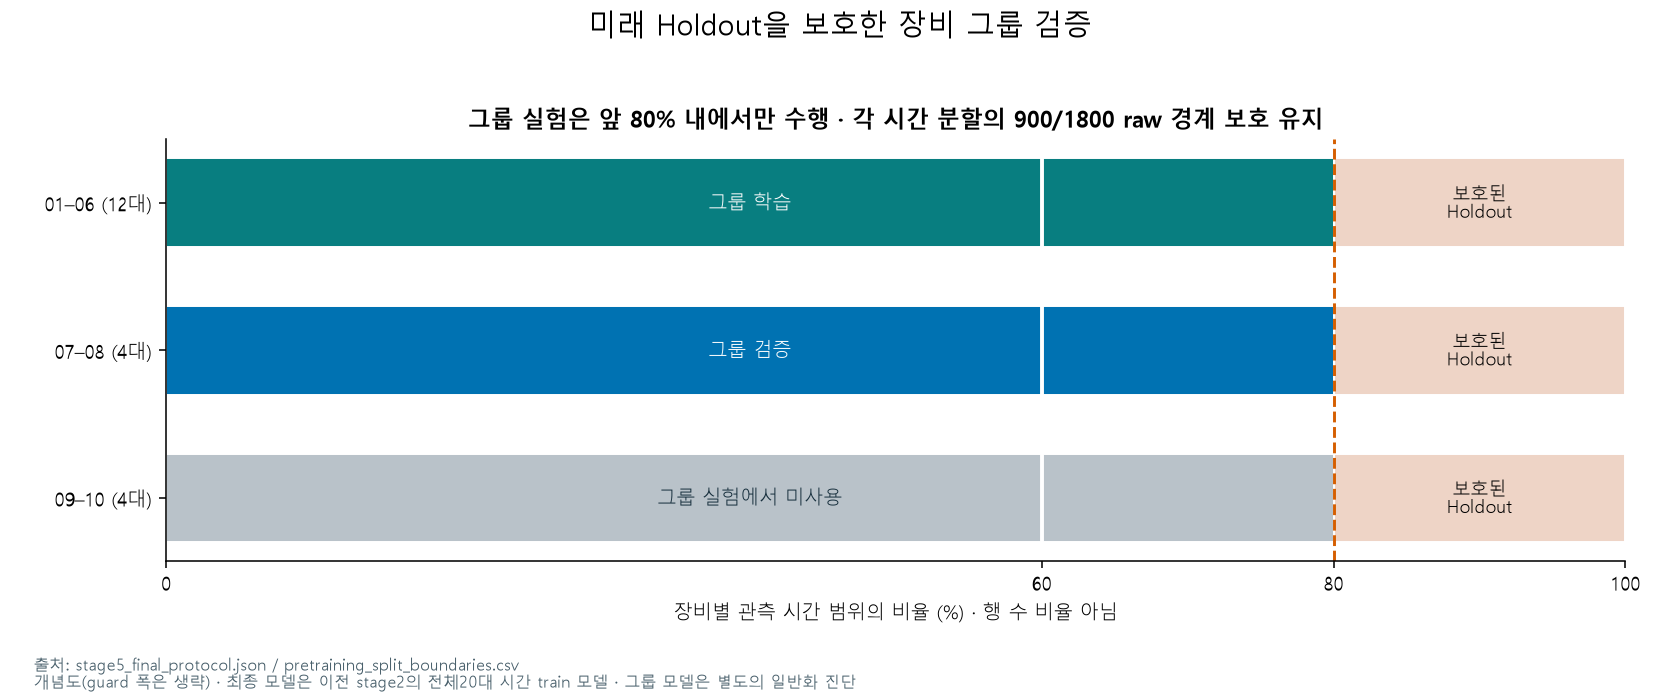

In [1]:
from pathlib import Path
import sys,json,hashlib
import numpy as np,pandas as pd
from IPython.display import display,Image
ROOT=Path.cwd()
if ROOT.name=='notebooks':ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.common import TABLES,CFG
assert Path(sys.executable).resolve()==Path(CFG['python']).resolve()
OUT=ROOT/'outputs/stage6'
def table(n):return pd.read_parquet(TABLES/(n+'.parquet'))
def figure(n):display(Image(filename=str(ROOT/('outputs/figures/final_evaluation/'+n+'.png'))))
def readjson(p):return json.loads(p.read_text(encoding='utf-8'))
def sha(p):return hashlib.sha256(p.read_bytes()).hexdigest()
frozen=readjson(OUT/'frozen_manifest.json')
access=readjson(OUT/'holdout_access.json')
assert access['status']=='complete' and access['full_prediction_passes']==1
assert not access['refit'] and not access['threshold_search']
print('실행 환경:',sys.executable,'| 최종 모델:',frozen['family'],'| Holdout 전체 추론:',access['full_prediction_passes'],'회')
figure('protected_split')

## 1. 보호된 그룹 검증

각 장비 앞80%의 기존 시간 train/validation 분할을 이용하고 각각 과거900/미래1800 raw guard를 유지했습니다.12대 학습/4대 validation입니다. 그룹 validation은 조기 종료와 임계값 선택에 사용했으므로 독립 시험이 아닙니다. 최대가용56개와 공통37개의 입력 가용 이벤트를 분리해 비교합니다. 기록 이벤트 분모는121개입니다.

,run_id,family,cohort,depth,weight_mode,device,positive_weight,train_rows,train_positive,validation_all_rows,validation_known_rows,validation_positive,iterations,encoded_features,train_seconds,AP_known,ROC_AUC_known,log_loss_known
0,A_base_maximum,A,maximum,3,unit,cuda:0,1.000000,588409,2097,1031622,321168,425,10,349,0.661178,0.001622,0.548903,0.012580
1,B_base_maximum,B,maximum,3,unit,cuda:0,1.000000,446724,1807,664295,213592,371,49,371,1.427280,0.005288,0.512233,0.015377
2,A_base_common,A,common,3,unit,cuda:0,1.000000,246923,1185,165040,62704,235,98,185,0.812388,0.094469,0.586055,0.028097
3,B_base_common,B,common,3,unit,cuda:0,1.000000,246923,1185,165040,62704,235,28,209,0.887434,0.041373,0.521478,0.025775
4,A_tuned_common,A,common,2,sqrt_train_neg_pos,cuda:0,14.400481,246923,1185,165040,62704,235,24,185,0.529179,0.013671,0.557121,0.111313
5,C_base_common,C,common,3,unit,cuda:0,1.000000,246923,1185,165040,62704,235,56,221,1.199729,0.041440,0.511810,0.027332


,run_id,budget_per_10000_raw,detected_events,available_events,recorded_events,alarm_episodes_per_10000_raw
1,A_base_common,5.0,1.0,37.0,121.0,3.819120
2,A_base_common,10.0,6.0,37.0,121.0,8.211107
5,A_base_maximum,5.0,0.0,56.0,121.0,0.000000
6,A_base_maximum,10.0,7.0,56.0,121.0,5.264424
9,A_tuned_common,5.0,0.0,37.0,121.0,0.000000
10,A_tuned_common,10.0,5.0,37.0,121.0,8.736236
13,B_base_common,5.0,7.0,37.0,121.0,3.492541
14,B_base_common,10.0,7.0,37.0,121.0,3.492541
17,B_base_maximum,5.0,5.0,56.0,121.0,2.992834
18,B_base_maximum,10.0,5.0,56.0,121.0,2.992834


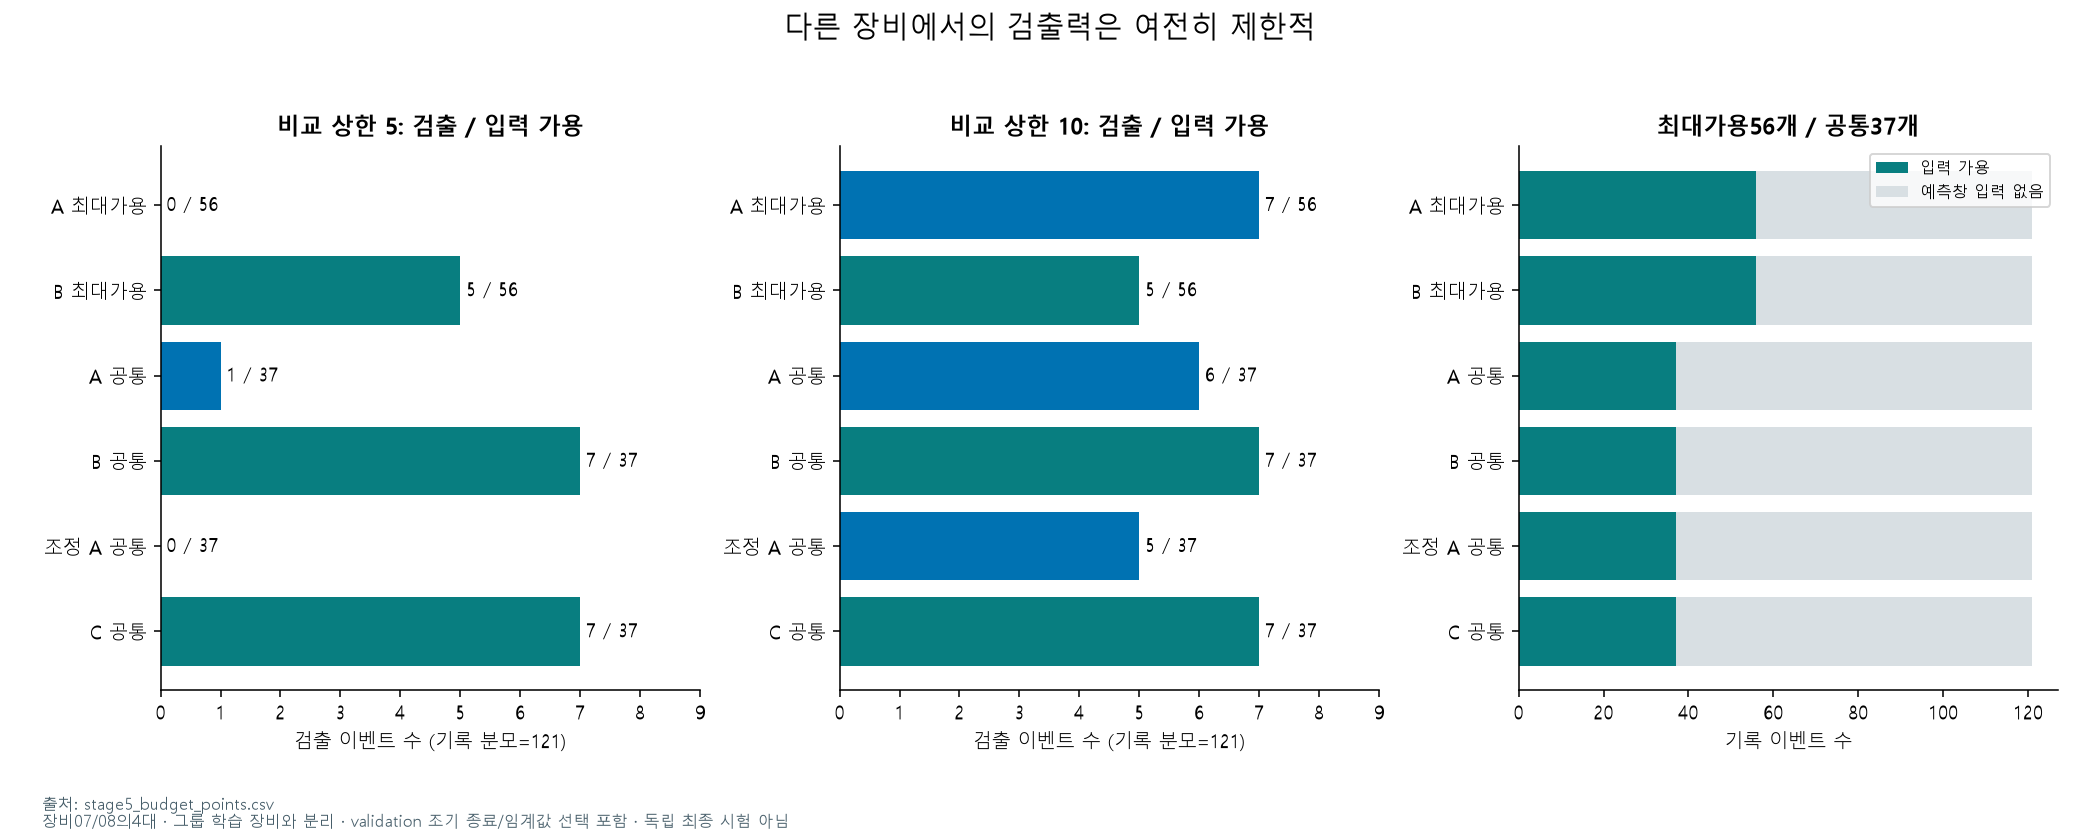

동결 전 그룹 검사 통과: 1170


In [2]:
runs=table('stage5_training_summary')
assert len(runs)==6 and runs.device.eq('cuda:0').all()
for rid in runs.run_id:
    config=readjson(ROOT/'outputs/stage5'/(rid+'_booster_config.json'))
    assert config['learner']['generic_param']['device']=='cuda:0'
checks5=readjson(ROOT/'outputs/validation/stage5_checks.json')
assert all(c['passed'] for c in checks5['checks'])
display(runs)
points5=table('stage5_budget_points')
display(points5[points5.budget_per_10000_raw.isin([5,10])][['run_id','budget_per_10000_raw','detected_events','available_events','recorded_events','alarm_episodes_per_10000_raw']])
figure('group_results')
print('동결 전 그룹 검사 통과:',len(checks5['checks']))

## 2. 모델과 숫자 임계값 동결

상한5/10 각각 시간·그룹 validation 중 낮은 기록 검출률을 취한 뒤 평균을 최대화하는 사전 규칙으로 B를 선택했습니다. 최종 모델은 기존 stage2의20대 시간 train 기준 모델입니다. 그룹 실험 모델을 최종 모델로 바꾼 것이 아니며 train+validation 재학습도 하지 않았습니다. 모든 동결 파일의 해시를 확인합니다.

,family,mean_worst_recall,mean_recall,mean_burden
0,B,0.033592,0.063765,4.070504
1,A,0.028017,0.031704,4.091356


,family,budget_per_10000_raw,validation,detected_events,recorded_events,recall_recorded,actual_burden,threshold
0,A,5,temporal_validation,3,232,0.012931,3.044310,0.010000
1,A,5,protected_group_validation,0,121,0.000000,0.000000,1.000000
2,A,10,temporal_validation,13,232,0.056034,8.056690,0.005533
3,A,10,protected_group_validation,7,121,0.057851,5.264424,0.015853
4,B,5,temporal_validation,6,232,0.025862,0.990719,0.003267
5,B,5,protected_group_validation,5,121,0.041322,2.992834,0.023481
6,B,10,temporal_validation,34,232,0.146552,9.305628,0.002999
7,B,10,protected_group_validation,5,121,0.041322,2.992834,0.023481


,operating_point,validation_budget_per_10000_raw,threshold,validation_detected,validation_recorded,validation_available,validation_actual_burden
0,validation_budget_5,5,0.003267,6,232,95,0.990719
1,validation_budget_10,10,0.002999,34,232,95,9.305628


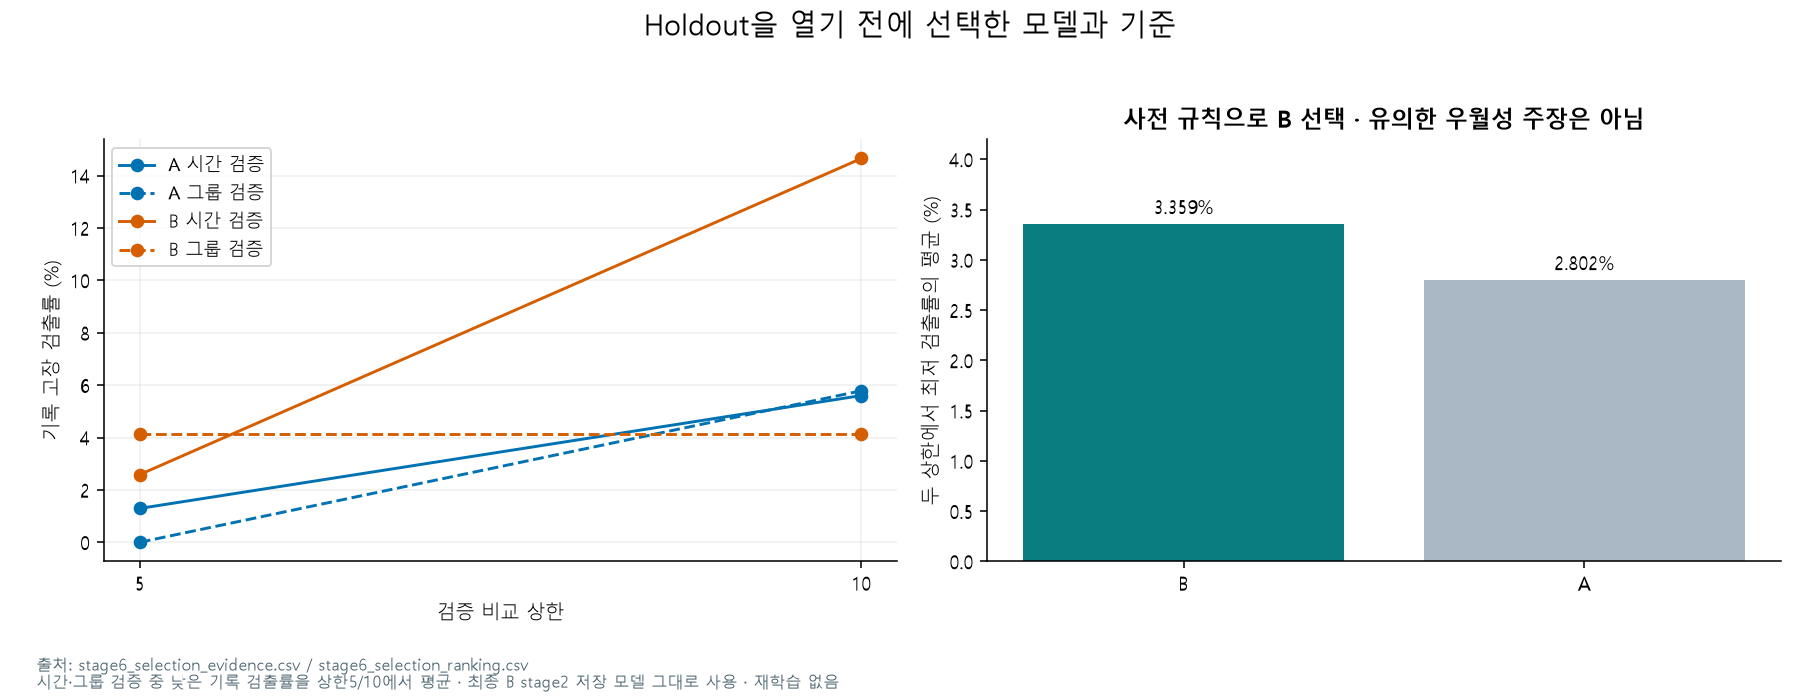

동결 파일 SHA256: 13 개 일치 · 동결 이후 재학습 없음


In [3]:
from datetime import datetime
assert datetime.fromisoformat(frozen['frozen_at_utc'])<datetime.fromisoformat(access['opened_at_utc'])
assert sha(OUT/'frozen_manifest.json')==access['frozen_manifest_sha256']
for path,digest in frozen['sha256'].items():assert sha(ROOT/path)==digest,path
display(table('stage6_selection_ranking'))
display(table('stage6_selection_evidence'))
display(pd.DataFrame(frozen['operating_points']))
figure('selection')
print('동결 파일 SHA256:',len(frozen['sha256']),'개 일치 · 동결 이후 재학습 없음')

## 3. 최종 Holdout의 두 고정 운영점

7/194개와33/194개를 검출했습니다. 입력 가용91개 기준은7.7%/36.3%이지만 입력 없는103개 고장도 전체 기록 분모에 포함합니다. 실제 경보 부담은0.815/9.899회/관측 지지길이10,000 raw입니다. 이는 전체 경보 부담이며 확정 오경보율이나 시간당 수치가 아닙니다. 두 임계값은 Holdout을 보기 전에 정해졌습니다.

,operating_point,threshold,detected_events,recorded_events,available_events,recall_recorded,recall_available,alarm_episodes_per_10000_raw,median_lead_raw
0,validation_budget_5,0.003267,7.0,194.0,91.0,0.036082,0.076923,0.814981,284.0
1,validation_budget_10,0.002999,33.0,194.0,91.0,0.170103,0.362637,9.898565,362.0


,operating_point,denominator,ci_low,ci_high,valid_samples,lead_p10,lead_median
0,validation_budget_5,available,0.031238,0.127673,2000,99.6,284.0
1,validation_budget_5,recorded,0.011493,0.060351,2000,99.6,284.0
2,validation_budget_10,available,0.220768,0.484211,2000,158.4,362.0
3,validation_budget_10,recorded,0.075267,0.255340,2000,158.4,362.0


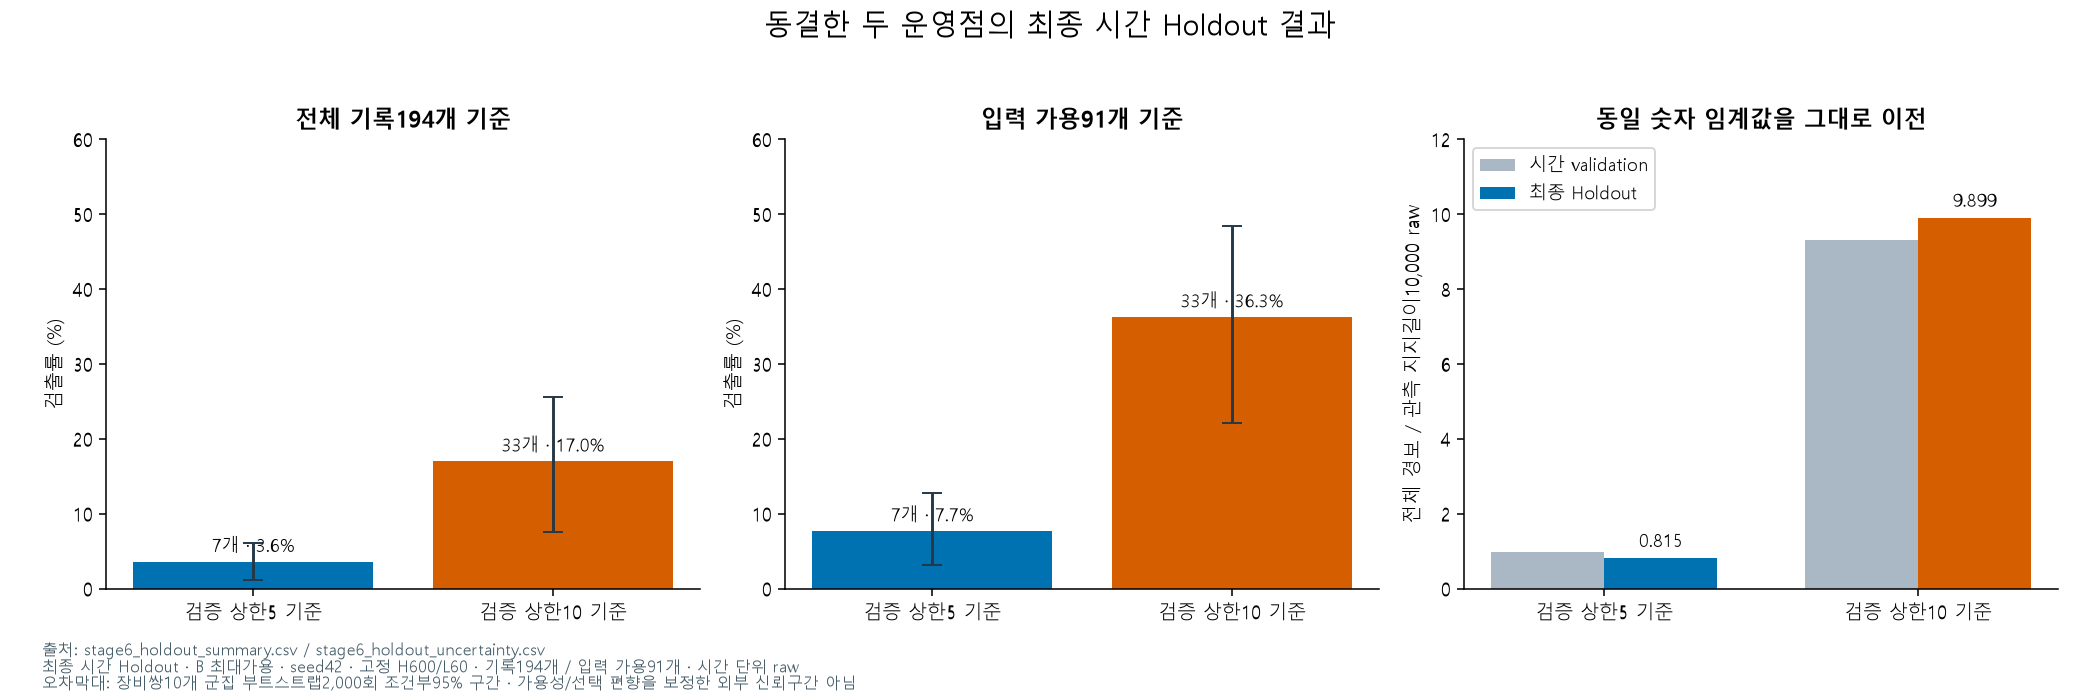

In [4]:
summary=table('stage6_holdout_summary')
events=table('stage6_holdout_events')
episodes=table('stage6_holdout_episodes')
predictions=pd.read_parquet(OUT/'holdout_predictions.parquet')
assert sha(OUT/'holdout_predictions.parquet')==access['prediction_sha256']
assert sha(TABLES/'stage6_holdout_summary.parquet')==access['summary_sha256']
assert len(summary)==len(frozen['operating_points'])==2
for point in frozen['operating_points']:
    r=summary[summary.operating_point.eq(point['operating_point'])].iloc[0]
    e=events[events.operating_point.eq(point['operating_point'])]
    a=episodes[episodes.operating_point.eq(point['operating_point'])]
    assert r.threshold==point['threshold']
    assert int(e.detected.sum())==r.detected_events
    assert int(e.available.sum())==r.available_events
    assert a.anchors.sum()==predictions.score.ge(point['threshold']).sum()
display(summary[['operating_point','threshold','detected_events','recorded_events','available_events','recall_recorded','recall_available','alarm_episodes_per_10000_raw','median_lead_raw']])
display(table('stage6_holdout_uncertainty'))
figure('holdout_results')

## 4. 장비별·경보별 부담과 라벨 불확실성

미확인 구간 시작 경보는 낮은 설정97.4%, 높은 설정94.5%입니다. NA를 정상이나 확정 오경보로 간주하지 않습니다. 알려진 라벨32,645행의 AP/ROC-AUC는 일부 정답이 확인된 분포에만 해당합니다. 군집 부트스트랩95% 구간은 장비쌍10개에 조건부이며 후보 선택이나 누락 편향을 보정하지 않습니다.

{'all_anchors': 736646,
 'known_anchors': 32645,
 'positive': 635,
 'AP_known': 0.06540965977293078,
 'ROC_AUC_known': 0.5011752970897381,
 'log_loss_known': 0.11481253057718277,
 'label_counts': {'2': 703931, '0': 32010, '1': 635, '3': 70}}

,recorded_events,tagged_events,scorable_events,available_events,detected_events,alarm_episodes,recall_recorded,recall_scorable,recall_available,alarms_MATCHED,alarms_KNOWN_NEGATIVE_START,alarms_POSITIVE_UNMATCHED,alarms_UNKNOWN_START,alarms_LATE_OR_EXCLUDED_START,median_lead_raw,Tool,observed_support_raw,operating_point
0,4,0,4,1,0,0,0.000000,0.000000,0.000000,0,0,0,0,0,NaN,01M01,1353396.0,validation_budget_5
1,20,0,20,19,2,402,0.100000,0.100000,0.105263,2,0,0,399,1,205.0,01M02,4076034.0,validation_budget_5
2,3,0,3,3,0,61,0.000000,0.000000,0.000000,0,0,0,61,0,NaN,02M01,1246390.0,validation_budget_5
3,4,0,4,0,0,67,0.000000,0.000000,NaN,0,0,0,67,0,NaN,02M02,1889554.0,validation_budget_5
4,6,0,6,2,1,185,0.166667,0.166667,0.500000,2,0,0,183,0,206.0,03M01,1775148.0,validation_budget_5
5,27,0,27,3,0,141,0.000000,0.000000,0.000000,0,0,0,141,0,NaN,03M02,2671668.0,validation_budget_5
6,0,0,0,0,0,114,NaN,NaN,NaN,0,0,0,114,0,NaN,04M01,2417356.0,validation_budget_5
7,18,0,18,13,2,114,0.111111,0.111111,0.153846,2,0,0,112,0,283.0,04M02,3089970.0,validation_budget_5
8,5,0,5,1,0,87,0.000000,0.000000,0.000000,0,0,0,86,1,NaN,05M01,2055240.0,validation_budget_5
9,8,0,8,0,0,655,0.000000,0.000000,NaN,0,0,0,655,0,NaN,05M02,489932.0,validation_budget_5


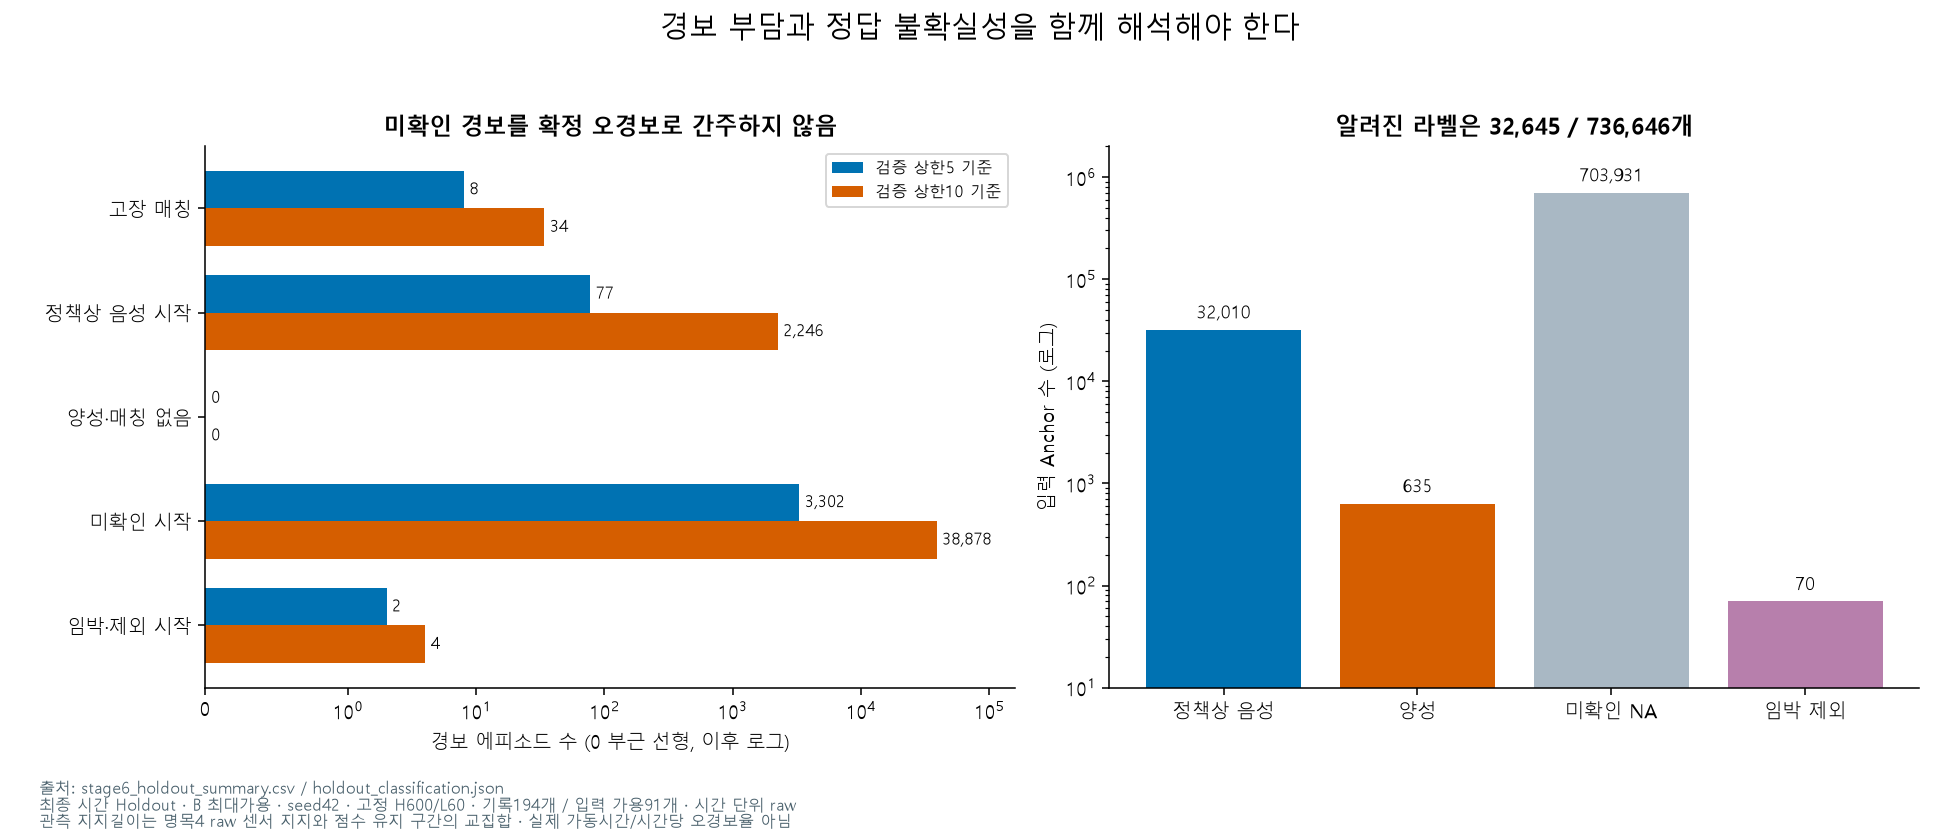

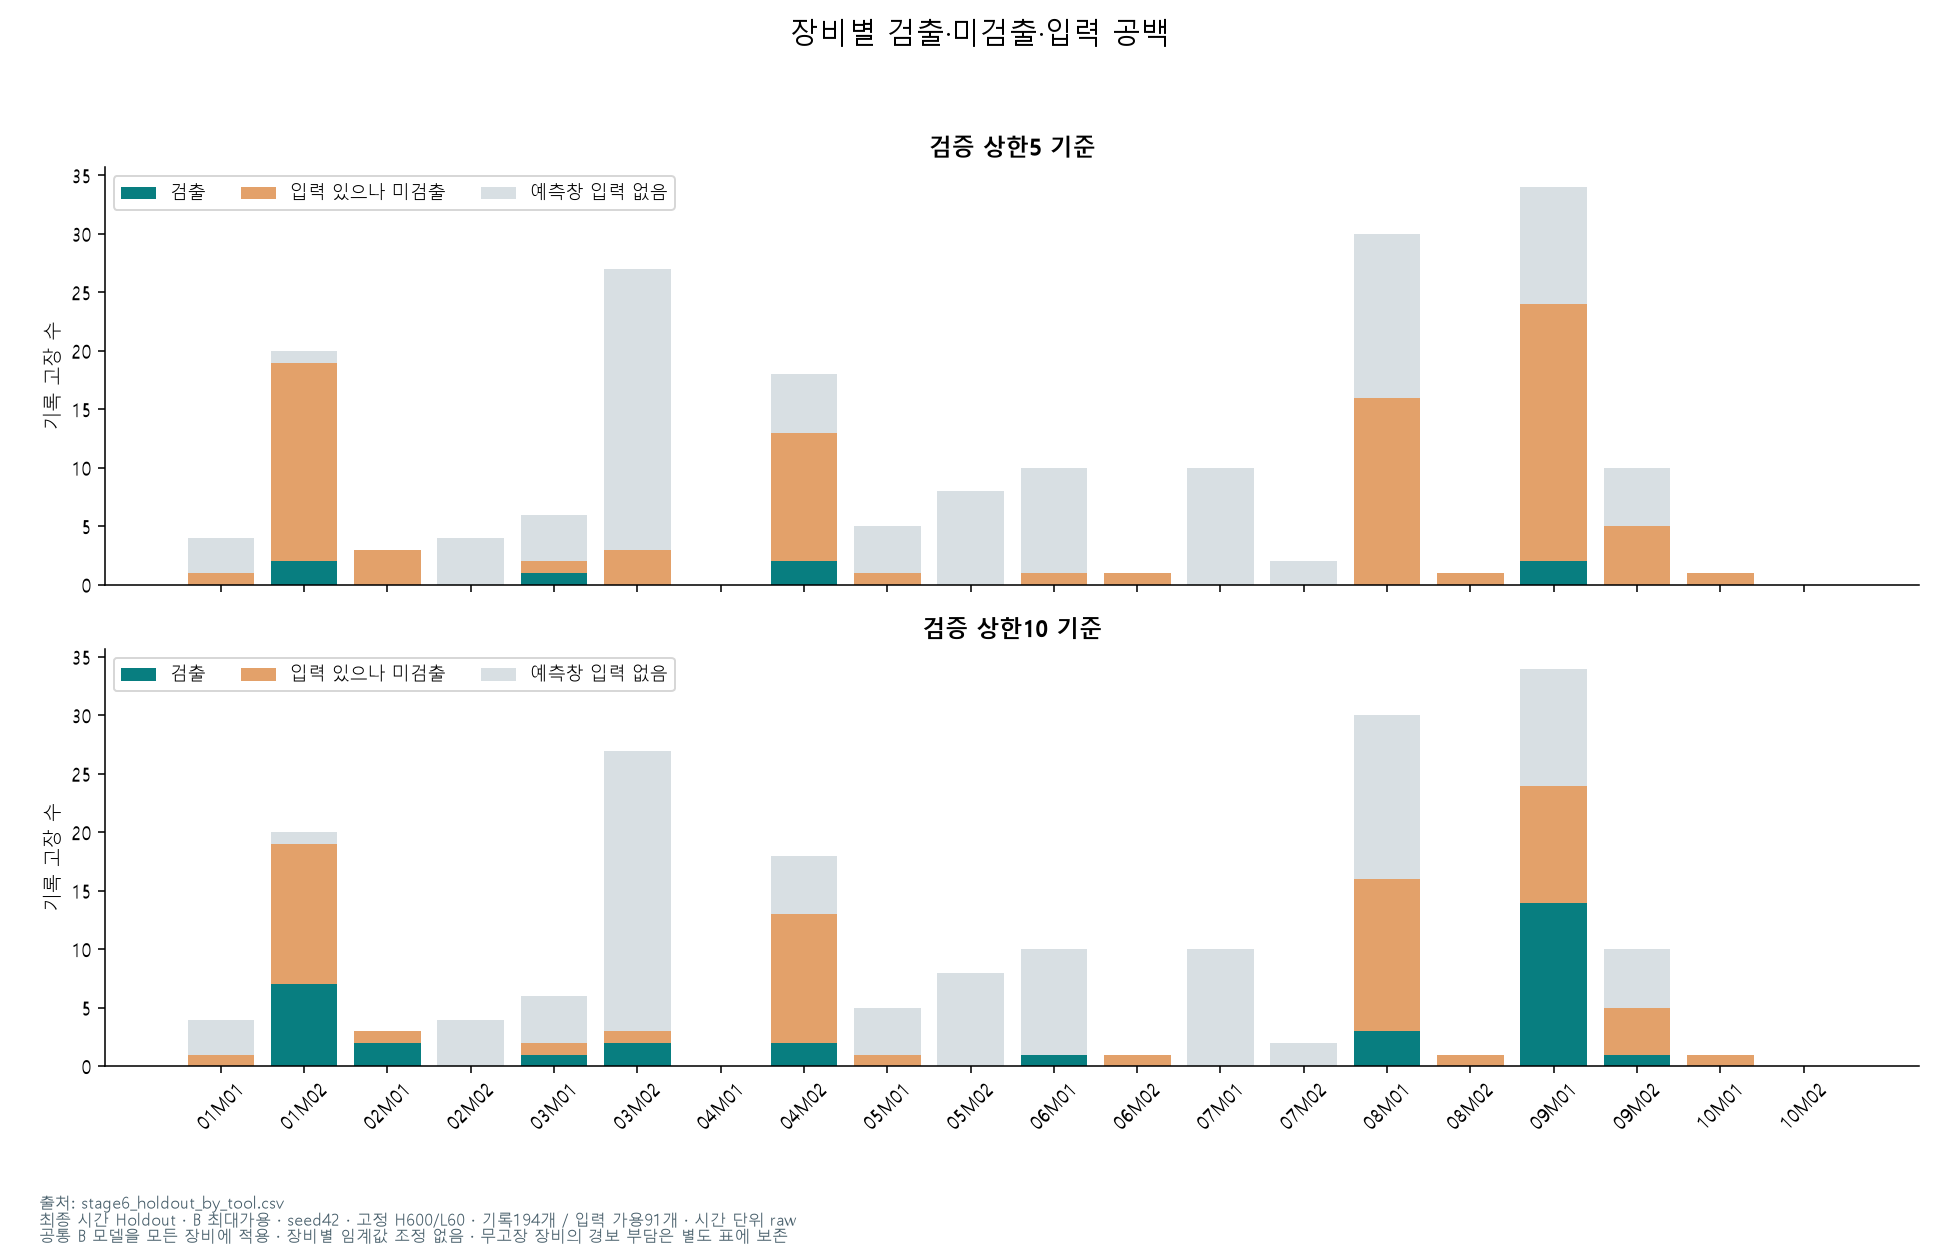

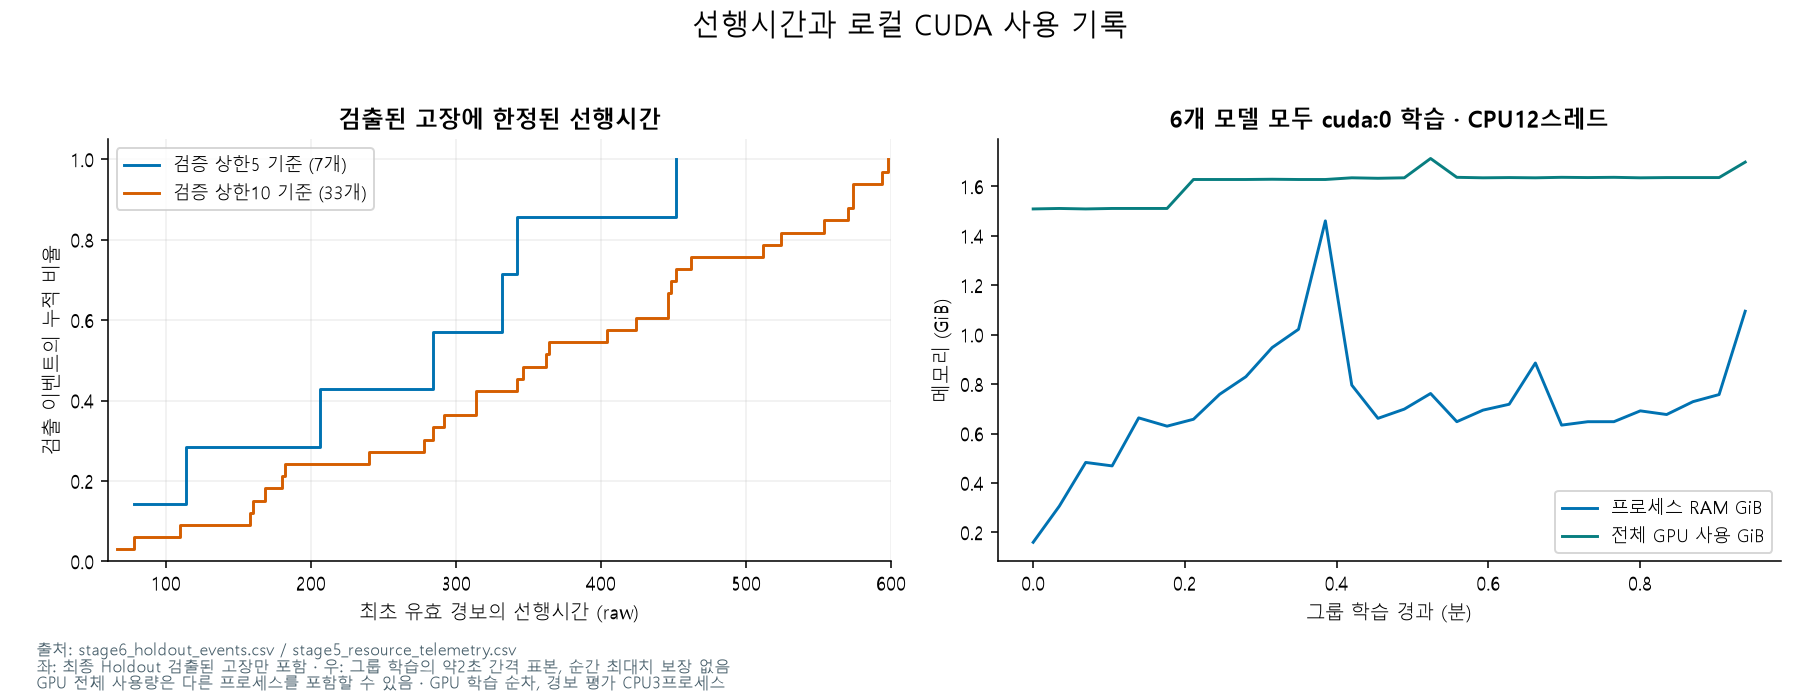

In [5]:
metrics=readjson(OUT/'holdout_classification.json')
known=predictions.audit_label.isin([0,1])
assert int(known.sum())==metrics['known_anchors']
assert int(predictions.audit_label.eq(1).sum())==metrics['positive']
display(metrics)
display(table('stage6_holdout_by_tool'))
figure('unknown_burden')
figure('by_tool')
figure('lead_resources')

## 5. 저장된 예측과 실제 센서의 사례

상한10 기준 검출 선행시간 중앙값에 가장 가까운 사례와 Tool/시각 순 첫 입력 가용 미검출 고장입니다. 사후 설명용 선정이며 모델/임계값에 반영하지 않습니다. 두 센서와 기존 점수만 표시하며 공백과 세그먼트 경계에서 선을 끊습니다.

,event_id,Tool,fault_time,detected,lead_raw,selection
0,01M02-low-77f4f5b40eea,01M02,35672222.0,True,362.0,검출 사례: 선행시간 중앙값에 가장 가까움
1,01M01-low-7fa51a916920,01M01,42056638.0,False,NaN,미검출 사례: Tool·시각 정렬의 첫 가용 고장


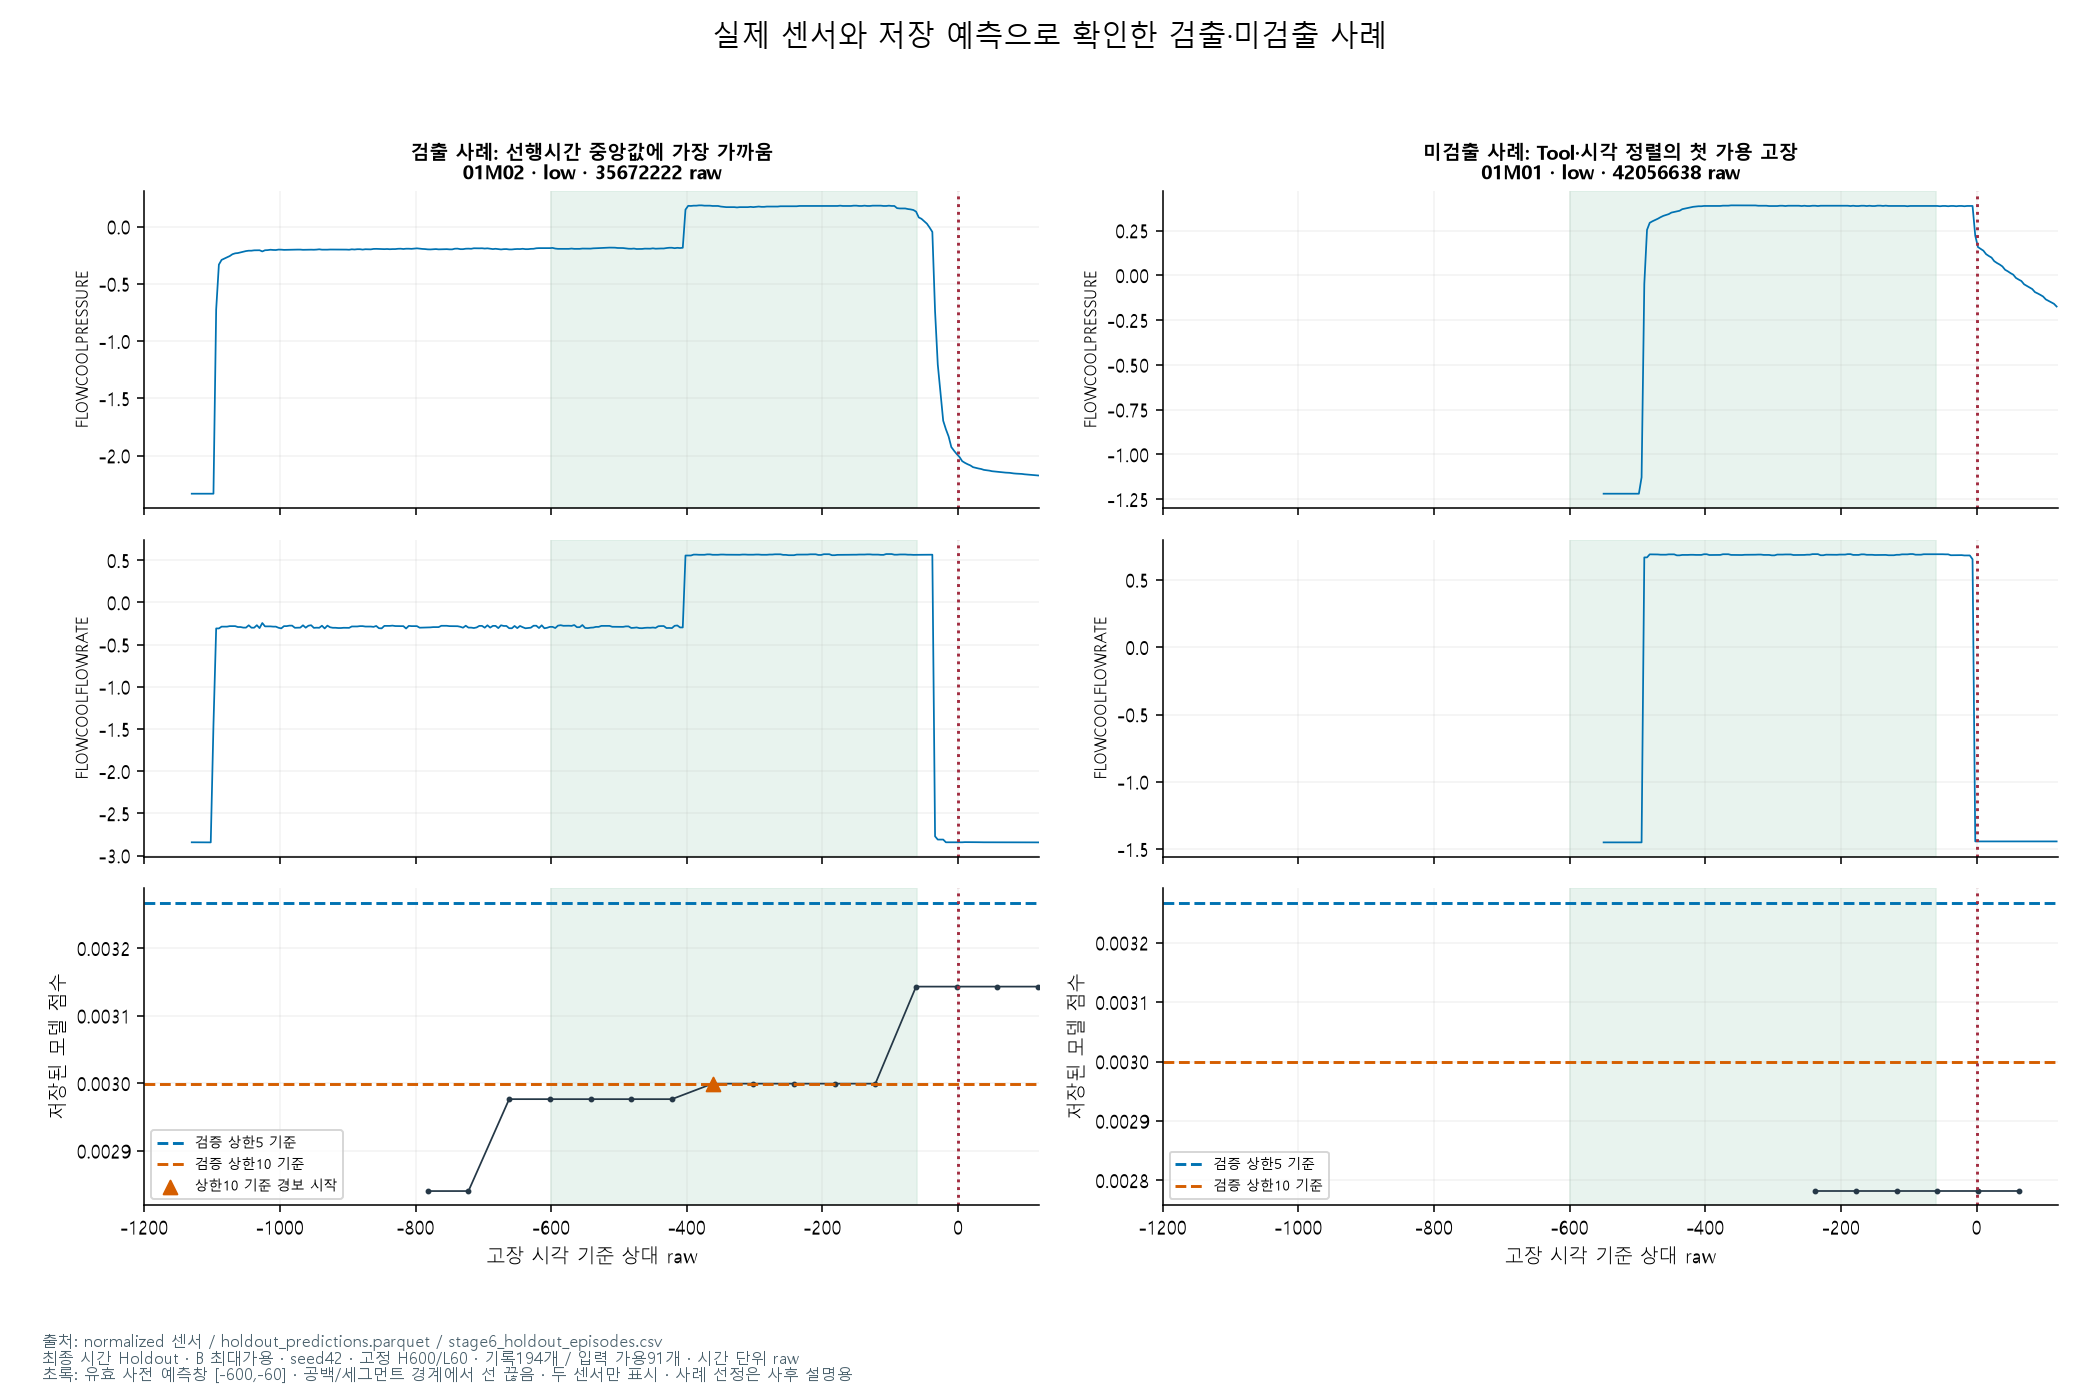

In [6]:
cases=readjson(OUT/'case_examples.json')
for c in cases:
    e=events[events.event_id.eq(c['event_id'])&events.operating_point.eq('validation_budget_10')].iloc[0]
    assert bool(e.detected)==c['detected'] and e.fault_time==c['fault_time']
display(pd.DataFrame([{k:v for k,v in c.items() if k!='query'} for c in cases]))
figure('event_cases')

## 6. 복구 이력·최종 검사와 결론

첫736,646행 추론을 저장한 뒤 빈 장비 이벤트 표의 concat으로 bool 열이 object가 되어 집계가 실패했습니다. 동결 소스/모델/임계값은 보존하고 별도 스크립트에서 저장 결과의 bool 자료형만 변환해 집계를 복구했습니다. 추가 추론0회입니다. 원래 실패 로그와 복구 해시를 아래에서 확인합니다.

현재는 연구 기준선으로 보존합니다. 입력 공백·미확인 이력·약한 장비 일반화가 해결되지 않아 자동 운영에 충분한 근거가 아닙니다. 후속 개선은 새 검증 데이터를 확보한 뒤 평가해야 합니다. 이번 구간을 반복 튜닝 후 독립 Holdout으로 재사용하지 않습니다. 초기 원본/전처리 품질 진단은 전 기간을 봤으므로 완전 맹검 외부 시험은 아닙니다.

In [7]:
recovery=readjson(OUT/'postprocessing_recovery.json')
assert recovery['postprocessing_only'] and recovery['additional_prediction_passes']==0
assert recovery['input_prediction_sha256']==sha(OUT/'holdout_predictions.parquet')
assert recovery['original_failure_log_sha256']==sha(ROOT/'outputs/stage6_holdout_evaluation.log')
assert recovery['recovery_script_sha256']==sha(ROOT/'scripts/recover_stage6_postprocessing.py')
checks6=readjson(ROOT/'outputs/validation/stage6_checks.json')
assert all(c['passed'] for c in checks6['checks']) and checks6['full_prediction_passes']==1
assert checks6['frozen_files_unchanged'] and checks6['no_reselection']
print('Holdout 실제 결과 검사:',len(checks6['checks']),'PASS')
print('이 Notebook: 기존 예측·표·그림 검증만 실행, 모델 추론 0회')
display(recovery)

Holdout 실제 결과 검사:

 123 PASS
이 Notebook: 기존 예측·표·그림 검증만 실행, 모델 추론 0회


{'started_at_utc': '2026-11-05T08:35:22.106962+00:00',
 'reason': '빈 장비 이벤트 표를 concat한 후 tagged가 object bool이 되어 ~ 연산 실패',
 'correction': '집계 이벤트 tagged/available/detected 열을 bool로 명시 변환',
 'postprocessing_only': True,
 'additional_prediction_passes': 0,
 'model_refit': False,
 'threshold_search': False,
 'input_prediction_sha256': 'cc6cb44efcafb6441c677fff2f0abf8cf0348bf6fdd462ee10e04fee79565221',
 'frozen_manifest_sha256': 'c211518ae97a6dcc93aa0198caf8ea368fef85efac5386cb3eecaced5ee9b3c1',
 'original_failure_log_sha256': '0cb7a4413a0cba809dbaf89fe8b87c7002a3b7446885be059e758b9f1d4a4e31',
 'recovery_script_sha256': '4dcdd4fb23b6f94ada90813bae360e03cc95e6f0bb0c7b305a4ac09e0bd8149c',
 'completed_at_utc': '2026-11-05T08:35:26.554334+00:00',
 'prediction_unchanged': True,
 'frozen_files_unchanged': True}